In [1]:

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from scipy import ndimage

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import IMAGE_DIR, METADATA_PATH, GROUND_TRUTH_PATH

RANDOM_STATE = 42

print("Project root:", PROJECT_ROOT)
print("Image directory:", IMAGE_DIR)
print("Metadata:", METADATA_PATH)
print("Ground truth:", GROUND_TRUTH_PATH)
print("Images directory exists:", Path(IMAGE_DIR).exists())


Project root: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project
Image directory: C:\Users\Kinjal Chatterjee\Downloads\MILK10k\images
Metadata: C:\Users\Kinjal Chatterjee\Downloads\MILK10k\metadata.csv
Ground truth: C:\Users\Kinjal Chatterjee\Downloads\MILK10k\supplements\training_gt.csv
Images directory exists: True


In [2]:

metadata = pd.read_csv(METADATA_PATH)
ground_truth = pd.read_csv(GROUND_TRUTH_PATH)

label_columns = [
    "AKIEC", "BCC", "BEN_OTH", "BKL", "DF",
    "INF", "MAL_OTH", "MEL", "NV", "SCCKA", "VASC"
]

ground_truth["label"] = ground_truth[label_columns].idxmax(axis=1)

# One dermoscopic image per lesion avoids counting paired images
# as separate samples in the baseline.
dermoscopic = metadata.loc[
    metadata["image_type"].str.lower().eq("dermoscopic")
].copy()

data = dermoscopic.merge(
    ground_truth[["lesion_id", "label"]],
    on="lesion_id",
    how="inner",
    validate="one_to_one"
)

print("Number of lesions:", data["lesion_id"].nunique())
print("Number of image rows:", len(data))
print("\nClass distribution:")
display(data["label"].value_counts().to_frame("count"))

display(data[["lesion_id", "isic_id", "label"]].head())


Number of lesions: 5240
Number of image rows: 5240

Class distribution:


,count
label,
BCC,2522
NV,746
BKL,544
SCCKA,473
MEL,450
AKIEC,303
DF,52
INF,50
VASC,47


,lesion_id,isic_id,label
0,IL_1612768,ISIC_0051817,SCCKA
1,IL_2547802,ISIC_0073863,NV
2,IL_8089688,ISIC_0076255,BCC
3,IL_5271098,ISIC_0077054,BCC
4,IL_4115404,ISIC_0078190,AKIEC


## Feature Extraction

Three feature sets are used for the classical machine-learning baseline:

- **Color features:** RGB channel statistics and color histograms.
- **Texture and edge features:** intensity variation, neighboring-pixel differences, Sobel gradients, local variance, and Laplacian response.
- **Combined features:** color, texture, and edge features concatenated into one vector.

The extracted features are calculated independently for each dermoscopic image. All images are resized to a common resolution to make feature extraction consistent.

In [3]:

def extract_features(image_path, size=(128, 128)):
    image = Image.open(image_path).convert("RGB").resize(size)
    rgb = np.asarray(image, dtype=np.float32)
    gray = rgb.mean(axis=2)

    features = {}

    # 1. Color features: 9 statistics
    channels = {
        "RED": rgb[:, :, 0],
        "GREEN": rgb[:, :, 1],
        "BLUE": rgb[:, :, 2],
    }

    for name, channel in channels.items():
        features[f"{name}_mean"] = channel.mean()
        features[f"{name}_std"] = channel.std()
        features[f"{name}_median"] = np.median(channel)

    # 2. Color histograms: 24 features, 8 bins per channel
    for name, channel in channels.items():
        hist, _ = np.histogram(channel, bins=8, range=(0, 256))
        hist = hist / channel.size

        for i, value in enumerate(hist, start=1):
            features[f"hist_bin{i}_{name[0]}"] = value

    color_features = features.copy()

    # 3. Texture and edge features
    texture = {}

    texture["gray_mean"] = gray.mean()
    texture["gray_std"] = gray.std()
    texture["gray_median"] = np.median(gray)

    # Neighboring-pixel differences
    texture["horizontal_diff_mean"] = np.abs(
        gray[:, 1:] - gray[:, :-1]
    ).mean()

    texture["vertical_diff_mean"] = np.abs(
        gray[1:, :] - gray[:-1, :]
    ).mean()

    # Sobel edge magnitude
    gx = ndimage.sobel(gray, axis=1)
    gy = ndimage.sobel(gray, axis=0)
    magnitude = np.hypot(gx, gy)

    texture["sobel_mean"] = magnitude.mean()
    texture["sobel_std"] = magnitude.std()
    texture["edge_density"] = (magnitude > 100).mean()

    # Local variance as a roughness measure
    local_mean = ndimage.uniform_filter(gray, size=9)
    local_sq_mean = ndimage.uniform_filter(gray ** 2, size=9)
    local_variance = np.maximum(
        local_sq_mean - local_mean ** 2, 0
    )

    texture["local_variance_mean"] = local_variance.mean()

    # Laplacian variance as a sharpness measure
    texture["laplacian_variance"] = ndimage.laplace(gray).var()

    return color_features, texture


In [4]:

feature_path = PROJECT_ROOT / "reports" / "classical_ml_features.csv"
feature_path.parent.mkdir(parents=True, exist_ok=True)

if feature_path.exists():
    features_df = pd.read_csv(feature_path)
    print("Loaded cached features:", features_df.shape)

else:
    color_rows = []
    texture_rows = []
    valid_indices = []

    start_time = time.time()

    for i, row in enumerate(data.itertuples(index=False)):
        image_path = Path(IMAGE_DIR) / f"{row.isic_id}.jpg"

        try:
            color, texture = extract_features(image_path)
            color_rows.append(color)
            texture_rows.append(texture)
            valid_indices.append(i)
        except Exception as exc:
            print(f"Skipping {row.isic_id}: {exc}")

        if (i + 1) % 500 == 0:
            print(f"Processed {i + 1}/{len(data)} images")

    valid_data = data.iloc[valid_indices].reset_index(drop=True)

    color_df = pd.DataFrame(color_rows).reset_index(drop=True)
    texture_df = pd.DataFrame(texture_rows).reset_index(drop=True)

    features_df = pd.concat(
        [
            valid_data[["lesion_id", "isic_id", "label"]].reset_index(drop=True),
            color_df,
            texture_df
        ],
        axis=1
    )

    features_df.to_csv(feature_path, index=False)

    print(f"Extraction took {(time.time() - start_time) / 60:.1f} minutes")
    print("Saved to:", feature_path)

print("Feature table shape:", features_df.shape)
display(features_df.head())


Processed 500/5240 images
Processed 1000/5240 images
Processed 1500/5240 images
Processed 2000/5240 images
Processed 2500/5240 images
Processed 3000/5240 images
Processed 3500/5240 images
Processed 4000/5240 images
Processed 4500/5240 images
Processed 5000/5240 images
Extraction took 0.5 minutes
Saved to: c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports\classical_ml_features.csv
Feature table shape: (5240, 46)


,lesion_id,isic_id,label,RED_mean,RED_std,RED_median,GREEN_mean,GREEN_std,GREEN_median,BLUE_mean,...,gray_mean,gray_std,gray_median,horizontal_diff_mean,vertical_diff_mean,sobel_mean,sobel_std,edge_density,local_variance_mean,laplacian_variance
0,IL_1612768,ISIC_0051817,SCCKA,133.987915,28.018250,134.0,94.373047,29.591215,94.0,109.635376,...,112.665451,30.565382,112.333336,9.345574,7.979536,72.671066,48.190636,0.231567,257.361755,717.145630
1,IL_2547802,ISIC_0073863,NV,142.331787,41.737400,163.0,121.897461,42.468449,144.0,119.440186,...,127.889809,42.921768,150.333328,3.312869,3.243848,28.843506,24.595892,0.022888,80.726730,117.393051
2,IL_8089688,ISIC_0076255,BCC,190.873108,6.084906,192.0,146.983459,15.555275,147.0,124.914917,...,154.257156,10.742634,154.666672,2.867023,2.347790,21.204832,13.654648,0.001831,21.900928,61.431042
3,IL_5271098,ISIC_0077054,BCC,139.360229,17.686937,144.0,113.733582,19.530447,118.0,122.175354,...,125.089722,19.383579,130.000000,4.250513,4.723630,41.477905,60.587185,0.093201,175.806610,340.120819
4,IL_4115404,ISIC_0078190,AKIEC,154.384644,18.075802,157.0,100.043640,15.645064,101.0,86.827576,...,113.751953,16.594442,115.333336,2.496248,1.981914,19.179230,15.975856,0.007019,25.182919,76.753372


In [5]:

# Identify feature columns by their prefixes/names
metadata_columns = ["lesion_id", "isic_id", "label"]

color_columns = [
    c for c in features_df.columns
    if c.startswith(("RED_", "GREEN_", "BLUE_", "hist_bin"))
]

texture_columns = [
    c for c in features_df.columns
    if c not in metadata_columns + color_columns
]

print("Color features:", len(color_columns))
print("Texture/edge features:", len(texture_columns))
print("Combined features:", len(color_columns) + len(texture_columns))

# Keep only rows with valid labels and finite feature values
features_df = features_df.dropna(subset=["label"]).reset_index(drop=True)

y = features_df["label"]
indices = np.arange(len(features_df))

train_idx, test_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

feature_sets = {
    "Color": color_columns,
    "Texture + edges": texture_columns,
    "Combined": color_columns + texture_columns,
}

print("\nTraining samples:", len(train_idx))
print("Test samples:", len(test_idx))
print("Training classes:", y.iloc[train_idx].nunique())
print("Test classes:", y.iloc[test_idx].nunique())


Color features: 33
Texture/edge features: 10
Combined features: 43

Training samples: 4192
Test samples: 1048
Training classes: 11
Test classes: 11


In [6]:

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1500,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),
    "SVM": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("scaler", StandardScaler()),
        ("model", SVC(
            class_weight="balanced",
            kernel="rbf"
        ))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("variance", VarianceThreshold()),
        ("model", RandomForestClassifier(
            n_estimators=150,
            class_weight="balanced_subsample",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

results = []
trained_models = {}

minimum_class_count = y.iloc[train_idx].value_counts().min()
n_splits = min(3, int(minimum_class_count))

if n_splits < 2:
    raise ValueError(
        "At least one class has fewer than two training samples; "
        "cross-validation needs a revised split."
    )

cv = StratifiedKFold(
    n_splits=n_splits,
    shuffle=True,
    random_state=RANDOM_STATE
)

for feature_set_name, columns in feature_sets.items():
    X = features_df[columns].replace([np.inf, -np.inf], np.nan)

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]
    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    for model_name, model in models.items():
        print(f"Training {model_name} | {feature_set_name}...")

        start = time.time()

        cv_scores = cross_val_score(
            model,
            X_train,
            y_train,
            cv=cv,
            scoring="f1_macro",
            n_jobs=1
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        results.append({
            "Feature set": feature_set_name,
            "Model": model_name,
            "CV macro F1 mean": cv_scores.mean(),
            "CV macro F1 std": cv_scores.std(),
            "Test macro F1": f1_score(
                y_test, predictions,
                average="macro",
                zero_division=0
            ),
            "Test balanced accuracy": balanced_accuracy_score(
                y_test, predictions
            ),
            "Test accuracy": accuracy_score(y_test, predictions),
            "Seconds": time.time() - start
        })

        trained_models[(feature_set_name, model_name)] = model

results_df = pd.DataFrame(results).sort_values(
    "CV macro F1 mean", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Training Logistic Regression | Color...
Training SVM | Color...
Training Random Forest | Color...
Training Logistic Regression | Texture + edges...
Training SVM | Texture + edges...
Training Random Forest | Texture + edges...
Training Logistic Regression | Combined...
Training SVM | Combined...
Training Random Forest | Combined...


,Feature set,Model,CV macro F1 mean,CV macro F1 std,Test macro F1,Test balanced accuracy,Test accuracy,Seconds
0,Combined,SVM,0.2273,0.0203,0.2117,0.2450,0.3693,3.0495
1,Combined,Logistic Regression,0.2243,0.0047,0.2335,0.3062,0.3521,0.7905
2,Color,SVM,0.2104,0.0158,0.1886,0.2928,0.3311,2.8167
3,Combined,Random Forest,0.1918,0.0104,0.1741,0.1814,0.5887,1.8953
4,Color,Logistic Regression,0.1879,0.0056,0.2109,0.3283,0.3120,0.7089
5,Color,Random Forest,0.1839,0.0036,0.1769,0.1813,0.5868,1.7713
6,Texture + edges,Logistic Regression,0.1788,0.0047,0.1847,0.2334,0.2615,0.3314
7,Texture + edges,SVM,0.1705,0.0065,0.1825,0.2344,0.2891,2.5311
8,Texture + edges,Random Forest,0.1690,0.0017,0.1826,0.1822,0.5611,1.7091


In [7]:

# Select the winner using cross-validation only
best_row = results_df.loc[results_df["CV macro F1 mean"].idxmax()]

best_feature_set = best_row["Feature set"]
best_model_name = best_row["Model"]

best_model = trained_models[(best_feature_set, best_model_name)]
best_columns = feature_sets[best_feature_set]

X = features_df[best_columns].replace([np.inf, -np.inf], np.nan)
X_test = X.iloc[test_idx]
y_test = y.iloc[test_idx]

y_pred = best_model.predict(X_test)

print("Selected feature set:", best_feature_set)
print("Selected model:", best_model_name)
print(f"CV macro F1: {best_row['CV macro F1 mean']:.4f}")
print(f"Test macro F1: {f1_score(y_test, y_pred, average='macro', zero_division=0):.4f}")
print(f"Test balanced accuracy: {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Test accuracy: {accuracy_score(y_test, y_pred):.4f}")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=label_columns,
    zero_division=0
))


Selected feature set: Combined
Selected model: SVM
CV macro F1: 0.2273
Test macro F1: 0.2117
Test balanced accuracy: 0.2450
Test accuracy: 0.3693

Classification report:
              precision    recall  f1-score   support

       AKIEC       0.16      0.39      0.22        61
         BCC       0.78      0.40      0.53       504
     BEN_OTH       0.08      0.22      0.12         9
         BKL       0.20      0.07      0.11       109
          DF       0.02      0.20      0.03        10
         INF       0.00      0.00      0.00        10
     MAL_OTH       0.00      0.00      0.00         2
         MEL       0.34      0.41      0.37        90
          NV       0.59      0.52      0.55       149
       SCCKA       0.28      0.37      0.32        95
        VASC       0.06      0.11      0.08         9

    accuracy                           0.37      1048
   macro avg       0.23      0.25      0.21      1048
weighted avg       0.55      0.37      0.42      1048



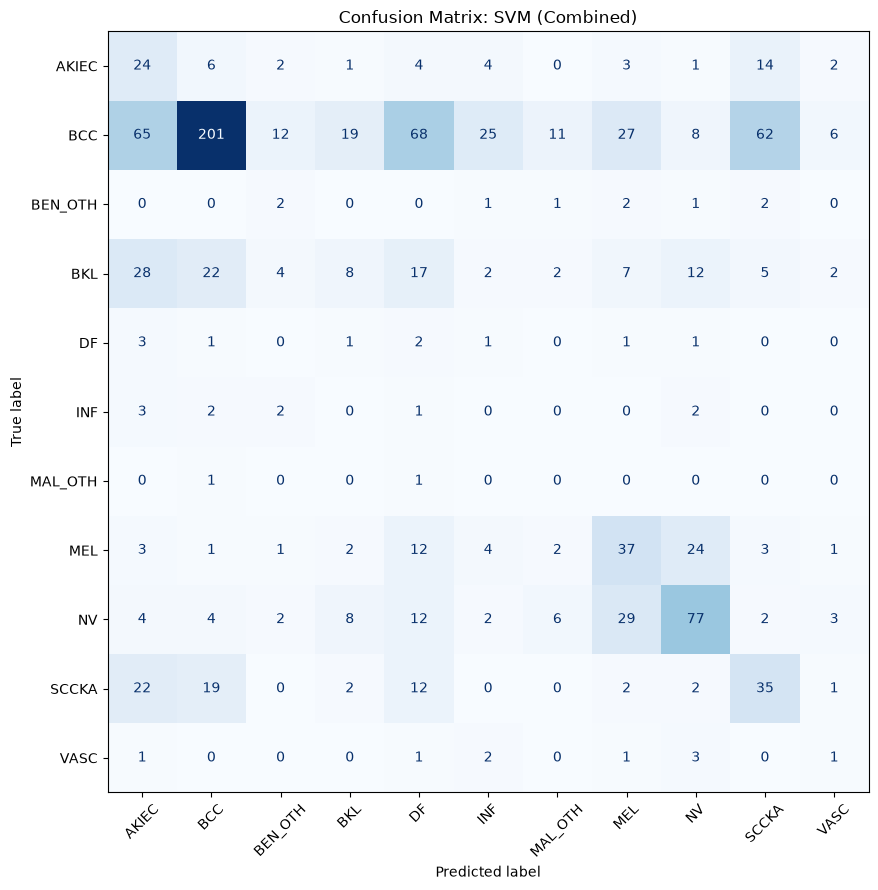

In [8]:

fig, ax = plt.subplots(figsize=(11, 9))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=label_columns,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

ax.set_title(f"Confusion Matrix: {best_model_name} ({best_feature_set})")
plt.tight_layout()
plt.show()


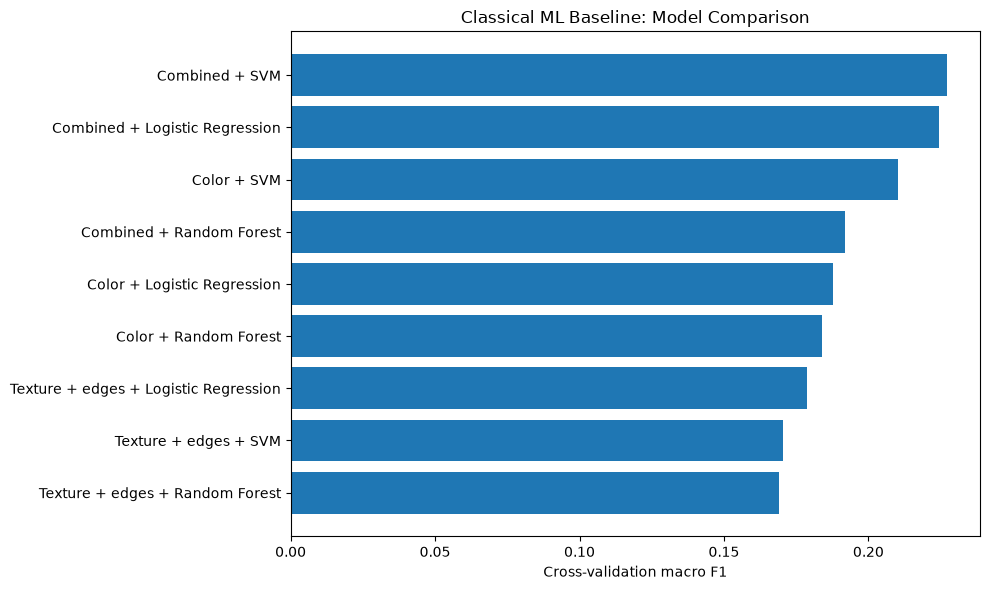

In [9]:

plot_data = results_df.sort_values("CV macro F1 mean", ascending=True)

plot_data["Configuration"] = (
    plot_data["Feature set"] + " + " + plot_data["Model"]
)

plt.figure(figsize=(10, 6))
plt.barh(plot_data["Configuration"], plot_data["CV macro F1 mean"])
plt.xlabel("Cross-validation macro F1")
plt.title("Classical ML Baseline: Model Comparison")
plt.tight_layout()
plt.show()


In [10]:

reports_dir = PROJECT_ROOT / "reports"
reports_dir.mkdir(parents=True, exist_ok=True)

# Save the full model comparison
results_df.to_csv(
    reports_dir / "classical_ml_model_comparison.csv",
    index=False
)

# Save per-class test metrics
report_dict = classification_report(
    y_test,
    y_pred,
    labels=label_columns,
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report_dict).T.to_csv(
    reports_dir / "classical_ml_classification_report.csv"
)

# Save the confusion matrix values
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred, labels=label_columns)

pd.DataFrame(
    cm,
    index=label_columns,
    columns=label_columns
).to_csv(reports_dir / "classical_ml_confusion_matrix.csv")

print("Saved comparison, classification report, and confusion matrix to:")
print(reports_dir)


Saved comparison, classification report, and confusion matrix to:
c:\Users\Kinjal Chatterjee\Desktop\MILK10K-Project\reports


## Results and Discussion

Nine configurations were evaluated using three feature sets: color, texture and edges, and combined features. The classifiers were Logistic Regression, Support Vector Machine (SVM), and Random Forest.

The best configuration was selected according to mean cross-validation macro F1-score. In the initial experiment, the combined feature set with SVM achieved the highest cross-validation macro F1-score of 0.2273. Its held-out test macro F1-score was 0.2117.

Combined features with Logistic Regression achieved a cross-validation macro F1-score of 0.2243 and a test macro F1-score of 0.2335. This illustrates that the ranking of configurations can differ between cross-validation and a particular test split.

Overall, the results suggest that simple handcrafted color, texture, and edge features provide limited performance for this imbalanced 11-class classification task. The large differences in class frequencies make macro F1 and balanced accuracy particularly important. Results for rare classes should be interpreted cautiously because the number of test examples is small.

This experiment provides a classical machine-learning baseline rather than a clinically validated diagnostic system. Future work could investigate more informative image features, hyperparameter tuning, and additional validation.